# Credit Risk, Credit Scores and Loan Approval
## Complete combined course notebook

**Source course:** [Credit Risk Modelling & Credit Scoring with Machine Learning,
Christ Raharja](https://www.udemy.com/course/credit-risk-modelling-credit-scoring-with-machine-learning/).
Adapted from all 12 Python resources supplied in your course ZIP. The course's
model families and predictors are preserved; execution, preprocessing and
evaluation errors are corrected and explained below.

**Run in Google Colab:** open this notebook and select **Runtime > Run all**.
All three CSV datasets are included in a compressed data cell; no separate CSV
upload or Kaggle login is required. Standard data-science libraries are used;
the setup cell installs imbalanced-learn only if a working version is missing.
The final Gradio interface is optional and has its own launch switch.

There are **three independent tasks**, with different datasets and outcomes:

| Task | Dataset | Models | Outcome |
|---|---|---|---|
| Loan default prediction | credit_risk_dataset.csv | Logistic Regression, Random Forest, KNN | loan_status: 1 = default |
| Numerical credit-score prediction | credit_score.csv | Decision Tree Regressor | CREDIT_SCORE supplied in the dataset |
| Loan-approval demonstration | loan.csv | MLPClassifier + SMOTE | Approved versus Denied |

The numerical score is the dataset's target, not a verified bureau score. Loan
approval labels and loan-default outcomes represent different prediction tasks.
The loan-approval dataset contains just **61 rows**: its results are a learning
demonstration and should not be presented as strong evidence of generalization.

The two main datasets are copied unchanged from the supplied nested
`Credit+Dataset.zip`. `loan.csv` comes from the exact public dataset referenced
by the supplied MLP script:
[Simple Loan Classification Dataset](https://www.kaggle.com/datasets/sujithmandala/simple-loan-classification-dataset).
The bundled snapshot avoids a hard-coded Kaggle path or a changing download.


### What was corrected

- All repeated uploads/imports are combined, with unique names for each task.
- The original default-risk scripts fitted preprocessing before the split.
  Here each model has its own pipeline, fitted only on training rows and within
  each cross-validation fold. Exact duplicate default-risk records are removed
  before splitting so identical records cannot appear in both partitions.
- Applicant prediction uses the **same fitted pipeline** as training. The
  original manual prediction functions bypassed numeric scaling; the MLP script
  also created one-row dummy columns inconsistently.
- The default-risk models keep the course's **seven final predictors**. The
  original scripts selected loan amount and then dropped it; it is therefore used
  for EDA, but is not requested as an unused input to the predictor.
- Missing-value dropping is shown as the course's cleaning demonstration.
  The modelling data retain missing predictors for training-only imputation,
  consistent with the course's modelling scripts.
- The course calls `loan_percent_income` a debt-to-income ratio. Here it is
  labelled **loan-to-income ratio**, since a full debt-service ratio is not
  supplied in this dataset.
- The same train/test split and five stratified CV folds are used for all three
  default classifiers. CV selects the demo's preferred model before test labels
  are evaluated. The test set is not used to tune thresholds or parameters.
- The decision-tree and MLP sections now report held-out metrics and do not stop
  `Run all` with blocking `input()` prompts. Gradio is an optional separate step.

These corrections can change results compared with the instructor's original
scripts. No additional model families or WOE/IV scorecard workflow are introduced.


## 1. Setup


In [1]:
from pathlib import Path
import base64
import hashlib
import importlib
import io
import json
import os
import subprocess
import sys
import time
from zipfile import ZipFile

# Modest CPU limits keep the run responsive on Colab and ordinary laptops.
os.environ.setdefault('GRADIO_ANALYTICS_ENABLED', 'False')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, make_scorer, mean_absolute_error, mean_squared_error,
    precision_score, recall_score, r2_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import cross_validate, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbalancedPipeline
except ImportError:
    # This version also supports newer sklearn releases where old imblearn fails.
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           '--upgrade', 'imbalanced-learn==0.14.2'])
    for module_name in list(sys.modules):
        if module_name == 'imblearn' or module_name.startswith('imblearn.'):
            del sys.modules[module_name]
    importlib.invalidate_caches()
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbalancedPipeline
import imblearn

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, 'to_string') else value)

SEED = 42
TEST_FRACTION = 0.20
CV_FOLDS = 5
MODEL_JOBS = 2
DATA_DIR = Path('course_credit_data')
OUTPUT_DIR = Path('course_credit_outputs')
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 150)
np.random.seed(SEED)
print('pandas', pd.__version__, '| sklearn', sklearn.__version__, '| imblearn', imblearn.__version__)


pandas 2.2.3 | sklearn 1.6.1 | imblearn 0.14.2


## 2. Restore the included datasets

Run this collapsed data cell once. It restores exactly three CSVs and verifies
their SHA-256 checksums. Its long encoded string contains data, not extra model
logic. Your original uploaded files are not modified.


In [2]:
#@title Restore included course CSV datasets
DATA_MANIFEST = {'credit_risk_dataset.csv': {'bytes': 1804682, 'sha256': 'ce3c6d2167717bf1627d1c0c81cbccd28323cd4aa7b96d542599366d5ff6aac8'}, 'credit_score.csv': {'bytes': 474750, 'sha256': 'd2c693c72f2337100f18364cf54af2326e4ba5e4e66c458c2dabecb174ca1f5a'}, 'loan.csv': {'bytes': 3453, 'sha256': '390fe3f0ac5e26e9f4fa1b7a45bc0ec0e685112bf25c54dc580743149960caa4'}}
BUNDLED_DATA = (
    '...'
)

with ZipFile(io.BytesIO(base64.b64decode(BUNDLED_DATA))) as archive:
    for filename, details in DATA_MANIFEST.items():
        raw = archive.read(filename)
        if hashlib.sha256(raw).hexdigest() != details['sha256']:
            raise ValueError(f'Data checksum failed: {filename}')
        (DATA_DIR / filename).write_bytes(raw)
        print('Ready:', filename, '| bytes:', len(raw))
del BUNDLED_DATA


Ready: credit_risk_dataset.csv | bytes: 1804682
Ready: credit_score.csv | bytes: 474750
Ready: loan.csv | bytes: 3453


## 3. Dataset overview and cleaning


In [3]:
risk_raw = pd.read_csv(DATA_DIR / 'credit_risk_dataset.csv')
score_raw = pd.read_csv(DATA_DIR / 'credit_score.csv')
approval_raw = pd.read_csv(DATA_DIR / 'loan.csv')

overview_rows = []
for label, frame in [('Default risk', risk_raw), ('Credit score', score_raw), ('Loan approval', approval_raw)]:
    overview_rows.append({
        'Task': label, 'Rows': len(frame), 'Columns': frame.shape[1],
        'Rows_with_missing_values': int(frame.isna().any(axis=1).sum()),
        'Exact_duplicate_rows': int(frame.duplicated().sum()),
    })
display(pd.DataFrame(overview_rows))
print('Default-risk first rows:')
display(risk_raw.head())
print('Default-risk last rows:')
display(risk_raw.tail())
print('Default-risk column types:')
display(risk_raw.dtypes.astype(str).rename('Type').to_frame())
print('Default-risk numeric summary:')
display(risk_raw.describe().round(2))
print('Default-risk missing values:')
display(risk_raw.isna().sum().rename('Missing').to_frame())

# Demonstrate the instructor's cleaning lesson without discarding the raw data.
risk_complete_cases_demo = risk_raw.dropna().drop_duplicates()
print('Complete-case cleaning demonstration:', risk_complete_cases_demo.shape)

# All modelling scripts use imputers. Keep their missing predictors, but remove
# exact repeated records before splitting to avoid duplicate overlap.
risk_data = risk_raw.drop_duplicates().reset_index(drop=True).copy()
score_data = score_raw.drop_duplicates().reset_index(drop=True).copy()
approval_data = approval_raw.drop_duplicates().reset_index(drop=True).copy()
for frame in [risk_data, score_data, approval_data]:
    for col in frame.select_dtypes(include=['object', 'string']).columns:
        frame[col] = frame[col].str.strip()
if risk_data['loan_status'].isna().any() or not risk_data['loan_status'].isin([0, 1]).all():
    raise ValueError('loan_status must have observed binary labels.')
if not set(approval_data['loan_status']).issubset({'Approved', 'Denied'}):
    raise ValueError('Unexpected loan-approval labels.')
print('Default-risk rows after exact deduplication:', len(risk_data))
print('Data-quality observations (retained to follow the supplied modelling data):')
print('Age >100:', int((risk_data['person_age'] > 100).sum()))
print('Employment length exceeding age:', int((risk_data['person_emp_length'] > risk_data['person_age']).sum()))
print('Review extreme records when interpreting this educational dataset.')


,Task,Rows,Columns,Rows_with_missing_values,Exact_duplicate_rows
0,Default risk,32581,12,3943,165
1,Credit score,1000,87,0,0
2,Loan approval,61,8,0,0


Default-risk first rows:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


Default-risk last rows:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26
32580,66,42000,RENT,2.0,MEDICAL,B,6475,9.99,0,0.15,N,30


Default-risk column types:


... (2 outputs left out)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


Default-risk missing values:


,Missing
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


Complete-case cleaning demonstration: (28501, 12)
Default-risk rows after exact deduplication: 32416
Data-quality observations (retained to follow the supplied modelling data):
Age >100: 5
Employment length exceeding age: 2
Review extreme records when interpreting this educational dataset.


## 4. One shared split for the default-risk models

The final predictors match the source scripts: four numeric and three
categorical fields. `loan_amnt` is deliberately absent, matching the instructor's
explicit drop. `loan_grade`, `loan_percent_income` and credit-history length are
also not used by these course classifiers. We preserve this choice to keep the
implementation aligned with the lessons.

EDA involving the target uses only the training partition. Missing predictors
are imputed inside model pipelines; the test data remain untouched during fitting.


In [4]:
RISK_NUMERIC = ['person_age', 'person_income', 'person_emp_length', 'loan_int_rate']
RISK_CATEGORICAL = ['person_home_ownership', 'loan_intent', 'cb_person_default_on_file']
RISK_FEATURES = RISK_NUMERIC + RISK_CATEGORICAL

risk_train, risk_test = train_test_split(
    risk_data, test_size=TEST_FRACTION, stratify=risk_data['loan_status'], random_state=SEED)
risk_train, risk_test = risk_train.copy(), risk_test.copy()
X_risk_train, X_risk_test = risk_train[RISK_FEATURES], risk_test[RISK_FEATURES]
y_risk_train = risk_train['loan_status'].astype(int)
y_risk_test = risk_test['loan_status'].astype(int)
assert set(risk_train.index).isdisjoint(risk_test.index)
print('Default-risk train:', len(risk_train), '| test:', len(risk_test))
print('Training class counts:', y_risk_train.value_counts().sort_index().to_dict())


Default-risk train: 25932 | test: 6484
Training class counts: {0: 20261, 1: 5671}


## 5. Loan-to-income, loan intent and default analysis

The first analysis reproduces the course's correlation and boxplot with the
correct label for `loan_percent_income`. The loan-intent table retains default
counts and average loan amounts among defaulters, and adds the group denominator
and default rate so differently sized groups can be compared.


Loan-to-income ratio vs binary default correlation: 0.3796


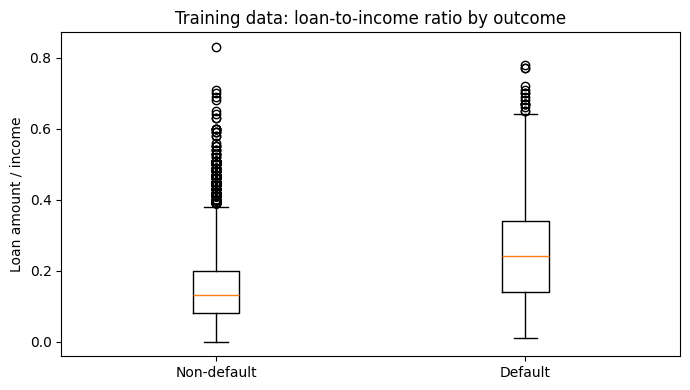

,loan_intent,Customers,Defaults,Default_Rate,Average_Loan_Amount,Average_Loan_Among_Defaults
0,MEDICAL,4842,1294,0.2672,9259.9029,11197.5657
1,DEBTCONSOLIDATION,4179,1173,0.2807,9583.1898,11039.1304
2,EDUCATION,5124,890,0.1737,9498.0582,10878.3427
3,PERSONAL,4356,859,0.1972,9626.3889,10689.8137
4,HOMEIMPROVEMENT,2821,761,0.2698,10293.5927,9949.3430
5,VENTURE,4610,694,0.1505,9592.3427,11264.0130


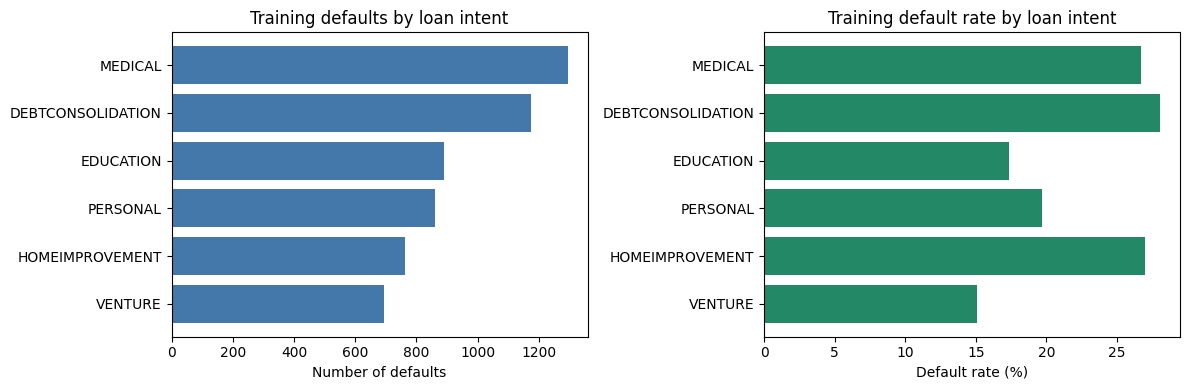

In [5]:
loan_income_correlation = risk_train['loan_percent_income'].corr(risk_train['loan_status'])
print(f'Loan-to-income ratio vs binary default correlation: {loan_income_correlation:.4f}')
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([risk_train.loc[risk_train.loan_status == value, 'loan_percent_income'].dropna()
            for value in [0, 1]])
ax.set_xticks([1, 2], ['Non-default', 'Default'])
ax.set(title='Training data: loan-to-income ratio by outcome', ylabel='Loan amount / income')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'loan_income_by_default.png', dpi=130)
plt.show()
plt.close(fig)

intent_summary = risk_train.groupby('loan_intent', observed=True).agg(
    Customers=('loan_status', 'size'), Defaults=('loan_status', 'sum'),
    Default_Rate=('loan_status', 'mean'), Average_Loan_Amount=('loan_amnt', 'mean'))
average_default_loan = risk_train.loc[risk_train.loan_status == 1].groupby('loan_intent')['loan_amnt'].mean()
intent_summary['Average_Loan_Among_Defaults'] = average_default_loan
intent_summary = intent_summary.sort_values('Defaults', ascending=False).reset_index()
display(intent_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(intent_summary['loan_intent'], intent_summary['Defaults'], color='#4477AA')
axes[0].set(title='Training defaults by loan intent', xlabel='Number of defaults')
axes[0].invert_yaxis()
axes[1].barh(intent_summary['loan_intent'], 100 * intent_summary['Default_Rate'], color='#228866')
axes[1].set(title='Training default rate by loan intent', xlabel='Default rate (%)')
axes[1].invert_yaxis()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'loan_intent_analysis.png', dpi=130)
plt.show()
plt.close(fig)


## 6. Train and cross-validate Logistic Regression, Random Forest and KNN

Each fold fits its own median/mode imputation, numeric scaling and one-hot
encoding. All three models use the same five training folds and default-risk
target. This extends the source's Random-Forest-only CV comparison to all three
models. No grid search is performed. A CPU is sufficient.

The Gradio demo's preferred model is chosen by **mean training-CV ROC-AUC**,
before held-out test evaluation. Accuracy, precision, recall, F1 and average
precision are also retained. The default classification threshold is 0.5,
matching the original scripts.


In [6]:
def make_risk_preprocessor():
    numeric = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    categorical = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return ColumnTransformer([
        ('num', numeric, RISK_NUMERIC),
        ('cat', categorical, RISK_CATEGORICAL),
    ])

risk_estimators = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=MODEL_JOBS),
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=MODEL_JOBS),
}
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_risk_train, y_risk_train))
scorers = {
    'Accuracy': 'accuracy',
    'Precision': make_scorer(precision_score, zero_division=0),
    'Recall': make_scorer(recall_score, zero_division=0),
    'F1': make_scorer(f1_score, zero_division=0),
    'ROC_AUC': 'roc_auc', 'Average_Precision': 'average_precision',
}
risk_models, risk_cv_details, cv_rows = {}, {}, []
started = time.perf_counter()
for name, estimator in risk_estimators.items():
    print(f'{name}: running {CV_FOLDS}-fold training CV...', flush=True)
    pipeline = Pipeline([('preprocessor', make_risk_preprocessor()), ('classifier', estimator)])
    with threadpool_limits(limits=MODEL_JOBS):
        scores = cross_validate(pipeline, X_risk_train, y_risk_train,
                                cv=cv_splits, scoring=scorers, n_jobs=1,
                                error_score='raise', return_train_score=False)
        pipeline.fit(X_risk_train, y_risk_train)
    risk_models[name] = pipeline
    risk_cv_details[name] = scores
    row = {'Model': name}
    for metric in scorers:
        row[f'CV_{metric}_Mean'] = float(np.mean(scores['test_' + metric]))
        row[f'CV_{metric}_Std'] = float(np.std(scores['test_' + metric]))
    cv_rows.append(row)
    print(f'  Done. Mean CV AUC={row["CV_ROC_AUC_Mean"]:.4f}; elapsed {time.perf_counter()-started:.1f}s')

risk_cv_results = pd.DataFrame(cv_rows).sort_values('CV_ROC_AUC_Mean', ascending=False).reset_index(drop=True)
PREFERRED_RISK_MODEL = risk_cv_results.loc[0, 'Model']
display(risk_cv_results.round(4))
print('Preferred model, selected using training CV:', PREFERRED_RISK_MODEL)


Logistic Regression: running 5-fold training CV...
  Done. Mean CV AUC=0.8018; elapsed 1.4s
Random Forest: running 5-fold training CV...
  Done. Mean CV AUC=0.8511; elapsed 22.2s
KNN: running 5-fold training CV...
  Done. Mean CV AUC=0.7616; elapsed 26.8s


,Model,CV_Accuracy_Mean,CV_Accuracy_Std,CV_Precision_Mean,CV_Precision_Std,CV_Recall_Mean,CV_Recall_Std,CV_F1_Mean,CV_F1_Std,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,CV_Average_Precision_Mean,CV_Average_Precision_Std
0,Random Forest,0.8517,0.0015,0.7435,0.0063,0.4918,0.0114,0.5919,0.0075,0.8511,0.0047,0.6988,0.0048
1,Logistic Regression,0.8126,0.0040,0.6489,0.0223,0.3126,0.0141,0.4217,0.0141,0.8018,0.0044,0.5631,0.0110
2,KNN,0.8154,0.0010,0.6263,0.0062,0.3872,0.0163,0.4783,0.0111,0.7616,0.0078,0.5106,0.0096


Preferred model, selected using training CV: Random Forest


## 7. Held-out default-risk comparison

These metrics belong to the same untouched test split. Positive-class precision,
recall and F1 refer to **default = 1**. Accuracy should be assessed alongside
default recall, ROC-AUC and average precision. The majority-class baseline
provides context. Differences from original video results are expected because
duplicates, split stratification and preprocessing leakage have been corrected.


Logistic Regression
              precision    recall  f1-score   support

 Non-default       0.84      0.96      0.89      5066
     Default       0.70      0.33      0.45      1418

    accuracy                           0.82      6484
   macro avg       0.77      0.65      0.67      6484
weighted avg       0.81      0.82      0.80      6484

Random Forest
              precision    recall  f1-score   support

 Non-default       0.87      0.96      0.91      5066
     Default       0.76      0.50      0.61      1418

    accuracy                           0.86      6484
   macro avg       0.82      0.73      0.76      6484
weighted avg       0.85      0.86      0.85      6484

KNN
              precision    recall  f1-score   support

 Non-default       0.85      0.94      0.89      5066
     Default       0.65      0.39      0.49      1418

    accuracy                           0.82      6484
   macro avg       0.75      0.67      0.69      6484
weighted avg       0.80      0.82   

,Model,Accuracy,Positive_Precision,Positive_Recall,Positive_F1,ROC_AUC,Average_Precision,Brier
0,Logistic Regression,0.8237,0.7037,0.3350,0.4539,0.8070,0.5926,0.1296
1,Random Forest,0.8572,0.7639,0.5021,0.6060,0.8585,0.7234,0.1060
2,KNN,0.8213,0.6522,0.3914,0.4892,0.7646,0.5266,0.1379
3,Majority baseline,0.7813,0.0000,0.0000,0.0000,0.5000,0.2187,0.1709


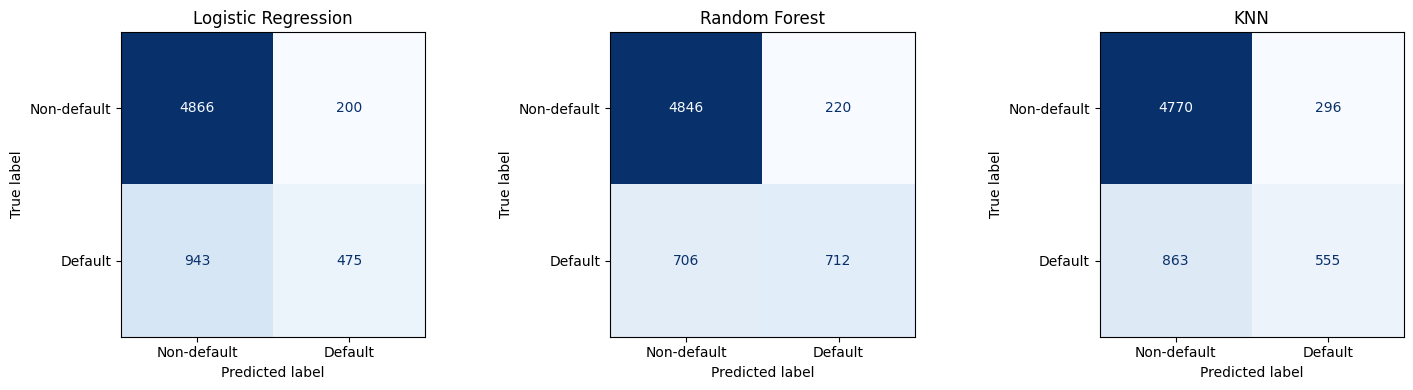

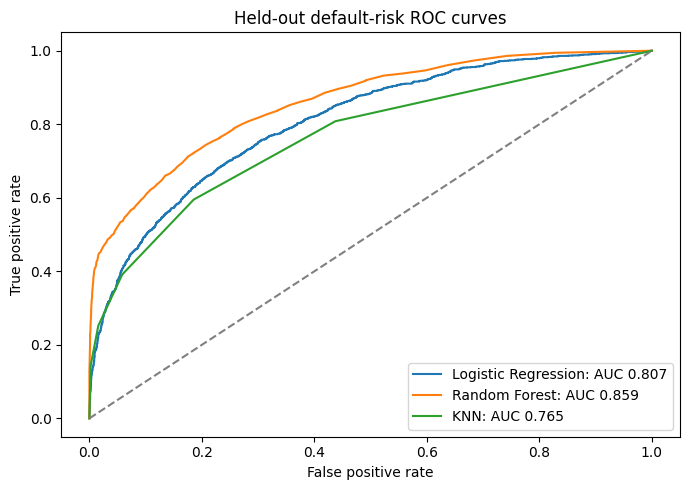

In [7]:
def binary_metrics(y, probability, predicted):
    return {
        'Accuracy': float(accuracy_score(y, predicted)),
        'Positive_Precision': float(precision_score(y, predicted, zero_division=0)),
        'Positive_Recall': float(recall_score(y, predicted, zero_division=0)),
        'Positive_F1': float(f1_score(y, predicted, zero_division=0)),
        'ROC_AUC': float(roc_auc_score(y, probability)),
        'Average_Precision': float(average_precision_score(y, probability)),
        'Brier': float(brier_score_loss(y, probability)),
    }

risk_test_probabilities, risk_test_predictions, risk_metric_rows = {}, {}, []
for name, pipeline in risk_models.items():
    with threadpool_limits(limits=MODEL_JOBS):
        probability = pipeline.predict_proba(X_risk_test)[:, list(pipeline.classes_).index(1)]
        predicted = pipeline.predict(X_risk_test)
    risk_test_probabilities[name], risk_test_predictions[name] = probability, predicted
    risk_metric_rows.append({'Model': name, **binary_metrics(y_risk_test, probability, predicted)})
    print(name)
    print(classification_report(y_risk_test, predicted, labels=[0, 1],
                                target_names=['Non-default', 'Default'], zero_division=0))

majority = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(y_risk_train), 1)), y_risk_train)
baseline_labels = majority.predict(np.zeros((len(y_risk_test), 1)))
baseline_probabilities = np.full(len(y_risk_test), float(y_risk_train.mean()))
risk_metric_rows.append({'Model': 'Majority baseline',
                         **binary_metrics(y_risk_test, baseline_probabilities, baseline_labels)})
risk_test_results = pd.DataFrame(risk_metric_rows)
display(risk_test_results.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, predicted) in zip(axes, risk_test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_risk_test, predicted, labels=[0, 1],
        display_labels=['Non-default', 'Default'], ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'default_confusion_matrices.png', dpi=130)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 5))
for name, probability in risk_test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_risk_test, probability)
    ax.plot(fpr, tpr, label=f'{name}: AUC {roc_auc_score(y_risk_test, probability):.3f}')
ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set(title='Held-out default-risk ROC curves', xlabel='False positive rate', ylabel='True positive rate')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'default_roc_curves.png', dpi=130)
plt.show()
plt.close(fig)


## 8. Default-risk interpretation and applicant prediction

Random Forest impurity importance is shown as a training-model diagnostic. It is
not a causal explanation. An applicant is passed as raw named columns through
the same fitted preprocessing and classifier; scaling/encoding are never
manually reconstructed.


In [8]:
forest = risk_models['Random Forest']
encoded_risk_features = forest.named_steps['preprocessor'].get_feature_names_out()
forest_importance = pd.DataFrame({
    'Encoded_Feature': encoded_risk_features,
    'Importance': forest.named_steps['classifier'].feature_importances_,
}).sort_values('Importance', ascending=False).reset_index(drop=True)
display(forest_importance.head(12))

def predict_default(age, income, emp_length, loan_int_rate, home_ownership,
                    loan_intent, default_history, model_name=None):
    selected = model_name or PREFERRED_RISK_MODEL
    if selected not in risk_models:
        raise ValueError(f'Unknown model: {selected}')
    if float(age) <= 0 or float(income) <= 0 or float(emp_length) < 0 or float(loan_int_rate) < 0:
        raise ValueError('Use positive age/income and non-negative tenure/interest rate.')
    applicant = pd.DataFrame([{
        'person_age': float(age), 'person_income': float(income),
        'person_emp_length': float(emp_length), 'loan_int_rate': float(loan_int_rate),
        'person_home_ownership': str(home_ownership).strip().upper(),
        'loan_intent': str(loan_intent).strip().upper(),
        'cb_person_default_on_file': str(default_history).strip().upper(),
    }], columns=RISK_FEATURES)
    pipeline = risk_models[selected]
    with threadpool_limits(limits=MODEL_JOBS):
        probability = float(pipeline.predict_proba(applicant)[0, list(pipeline.classes_).index(1)])
        predicted = int(pipeline.predict(applicant)[0])
    return {'Model': selected, 'Predicted_class': 'Default' if predicted else 'Non-default',
            'Estimated_default_probability': round(probability, 6), 'Classification_threshold': 0.5}

display(predict_default(35, 60000, 8, 11, 'RENT', 'PERSONAL', 'N'))


,Encoded_Feature,Importance
0,num__person_income,0.300578
1,num__loan_int_rate,0.295898
2,num__person_age,0.130725
3,num__person_emp_length,0.114176
4,cat__person_home_ownership_RENT,0.031933
5,cat__loan_intent_DEBTCONSOLIDATION,0.019154
6,cat__loan_intent_MEDICAL,0.016486
7,cat__loan_intent_HOMEIMPROVEMENT,0.015631
8,cat__person_home_ownership_MORTGAGE,0.014544
9,cat__person_home_ownership_OWN,0.011500


{'Model': 'Random Forest',
 'Predicted_class': 'Non-default',
 'Estimated_default_probability': 0.13,
 'Classification_threshold': 0.5}

## 9. Credit-score dataset: debt relationship and Decision Tree regression

This is the course's second dataset and a different target. Predictors are
`INCOME`, `SAVINGS`, `DEBT`, `CAT_CREDIT_CARD`, `DEFAULT`, exactly as in the
supplied regression script. `DEFAULT` is treated as the dataset's provided
customer-history field; the source does not establish its temporal definition.
The result estimates the supplied numerical score and is not calibrated to a
credit bureau. Do not interpret the score model's R² as default-classifier accuracy.


Training debt / credit-score correlation: -0.3192


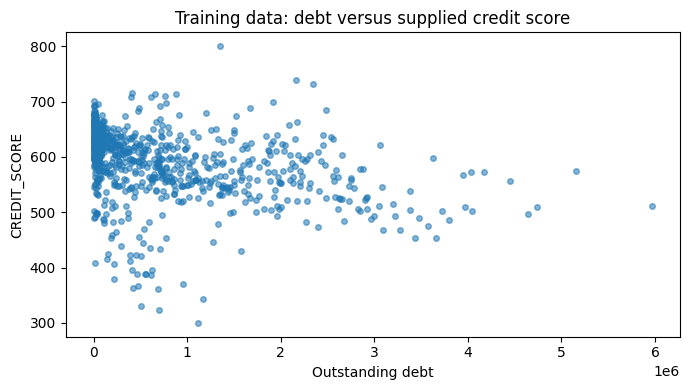

,Model,MAE,RMSE,R2
0,Decision Tree,35.3250,48.5581,0.4060
1,Mean baseline,48.8608,63.1307,-0.0041


Example predicted dataset credit score: 666.0


In [9]:
SCORE_FEATURES = ['INCOME', 'SAVINGS', 'DEBT', 'CAT_CREDIT_CARD', 'DEFAULT']
score_train, score_test = train_test_split(score_data, test_size=TEST_FRACTION, random_state=SEED)
score_train, score_test = score_train.copy(), score_test.copy()
X_score_train, X_score_test = score_train[SCORE_FEATURES], score_test[SCORE_FEATURES]
y_score_train, y_score_test = score_train['CREDIT_SCORE'], score_test['CREDIT_SCORE']

debt_score_correlation = score_train['DEBT'].corr(score_train['CREDIT_SCORE'])
print(f'Training debt / credit-score correlation: {debt_score_correlation:.4f}')
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(score_train['DEBT'], score_train['CREDIT_SCORE'], s=16, alpha=0.55)
ax.set(title='Training data: debt versus supplied credit score', xlabel='Outstanding debt', ylabel='CREDIT_SCORE')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'debt_credit_score.png', dpi=130)
plt.show()
plt.close(fig)

score_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', DecisionTreeRegressor(random_state=SEED)),
]).fit(X_score_train, y_score_train)
score_predictions = score_model.predict(X_score_test)
score_baseline = DummyRegressor(strategy='mean').fit(X_score_train, y_score_train)
regression_rows = []
for name, predictions in [('Decision Tree', score_predictions), ('Mean baseline', score_baseline.predict(X_score_test))]:
    regression_rows.append({'Model': name,
        'MAE': float(mean_absolute_error(y_score_test, predictions)),
        'RMSE': float(np.sqrt(mean_squared_error(y_score_test, predictions))),
        'R2': float(r2_score(y_score_test, predictions))})
score_results = pd.DataFrame(regression_rows)
display(score_results.round(4))

def predict_credit_score(income, savings, debt, cat_credit_card, default):
    if min(float(income), float(savings), float(debt)) < 0:
        raise ValueError('Income, savings and debt must be non-negative.')
    if cat_credit_card not in [0, 1] or default not in [0, 1]:
        raise ValueError('Credit-card and default indicators must be 0 or 1.')
    applicant = pd.DataFrame([{
        'INCOME': float(income), 'SAVINGS': float(savings), 'DEBT': float(debt),
        'CAT_CREDIT_CARD': int(cat_credit_card), 'DEFAULT': int(default),
    }], columns=SCORE_FEATURES)
    return round(float(score_model.predict(applicant)[0]), 2)

print('Example predicted dataset credit score:', predict_credit_score(60000, 20000, 10000, 1, 0))


## 10. Loan-approval demonstration: MLP + SMOTE

This follows the added course script: seven applicant fields, one-hot categorical
encoding, scaling, SMOTE and a neural network with hidden layers **(50, 25)** and
**max_iter=500**. Encoding/scaling are fitted on training rows only; SMOTE is
inside an imbalanced-learn pipeline and runs only while fitting.

The original script used one-row `get_dummies(drop_first=True)`, which can lose
the applicant's categorical values. A fitted full one-hot encoder fixes that
inconsistency. All categories seen during training are retained; an unseen
category is encoded as zeros for that field. This is particularly relevant to
the small dataset, where some test-set occupations do not occur in training.
SMOTE on encoded categorical variables can produce fractional dummy values;
this is retained as the course's educational method. The source dataset has only
61 records, so the 13-row test result is illustrative and highly uncertain.

For clarity, this notebook explicitly maps **Denied=0, Approved=1**. This differs
from LabelEncoder's alphabetical numeric ordering but preserves the label meanings.
The positive-class metrics in this section therefore concern **approval**, not default.


Loan-approval training rows: 48 | test rows: 13
Original training class counts: {0: 13, 1: 35}
              precision    recall  f1-score   support

      Denied       0.67      0.67      0.67         3
    Approved       0.90      0.90      0.90        10

    accuracy                           0.85        13
   macro avg       0.78      0.78      0.78        13
weighted avg       0.85      0.85      0.85        13



,Model,Accuracy,Positive_Precision,Positive_Recall,Positive_F1,ROC_AUC,Average_Precision,Brier
0,MLP + SMOTE (small educational sample),0.8462,0.9,0.9,0.9,0.9667,0.9909,0.0968


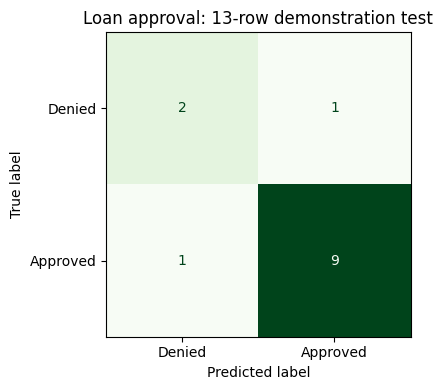

{'Demonstration_prediction': 'Approved',
 'Estimated_approval_probability': 0.99157,
 'Dataset_rows': 61}

In [10]:
APPROVAL_NUMERIC = ['age', 'income', 'credit_score']
APPROVAL_CATEGORICAL = ['gender', 'occupation', 'education_level', 'marital_status']
APPROVAL_FEATURES = APPROVAL_NUMERIC + APPROVAL_CATEGORICAL
APPROVAL_MAPPING = {'Denied': 0, 'Approved': 1}
approval_y = approval_data['loan_status'].map(APPROVAL_MAPPING).astype(int)
X_approval_train, X_approval_test, y_approval_train, y_approval_test = train_test_split(
    approval_data[APPROVAL_FEATURES], approval_y,
    test_size=TEST_FRACTION, stratify=approval_y, random_state=SEED)

approval_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), APPROVAL_NUMERIC),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), APPROVAL_CATEGORICAL),
])
smote_neighbors = min(5, int(y_approval_train.value_counts().min()) - 1)
if smote_neighbors < 1:
    raise ValueError('SMOTE requires at least two minority-class training records.')
approval_model = ImbalancedPipeline([
    ('preprocessor', approval_preprocessor),
    ('scaler', StandardScaler()),
    ('smote', SMOTE(k_neighbors=smote_neighbors, random_state=SEED)),
    ('classifier', MLPClassifier(hidden_layer_sizes=(50, 25), max_iter=500, random_state=SEED)),
])
with threadpool_limits(limits=MODEL_JOBS):
    approval_model.fit(X_approval_train, y_approval_train)
    approval_predictions = approval_model.predict(X_approval_test)
    approval_probabilities = approval_model.predict_proba(X_approval_test)[:, list(approval_model.classes_).index(1)]

print('Loan-approval training rows:', len(X_approval_train), '| test rows:', len(X_approval_test))
print('Original training class counts:', y_approval_train.value_counts().sort_index().to_dict())
print(classification_report(y_approval_test, approval_predictions, labels=[0, 1],
                           target_names=['Denied', 'Approved'], zero_division=0))
approval_results = pd.DataFrame([{'Model': 'MLP + SMOTE (small educational sample)',
    **binary_metrics(y_approval_test, approval_probabilities, approval_predictions)}])
display(approval_results.round(4))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_approval_test, approval_predictions,
    labels=[0, 1], display_labels=['Denied', 'Approved'], ax=ax, colorbar=False, cmap='Greens')
ax.set_title('Loan approval: 13-row demonstration test')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'approval_demo_confusion_matrix.png', dpi=130)
plt.show()
plt.close(fig)

def predict_loan_approval(age, gender, occupation, education_level, marital_status, income, credit_score):
    if float(age) <= 0 or float(income) < 0 or float(credit_score) < 0:
        raise ValueError('Use positive age and non-negative income/credit score.')
    applicant = pd.DataFrame([{
        'age': float(age), 'income': float(income), 'credit_score': float(credit_score),
        'gender': str(gender).strip(), 'occupation': str(occupation).strip(),
        'education_level': str(education_level).strip(), 'marital_status': str(marital_status).strip(),
    }], columns=APPROVAL_FEATURES)
    with threadpool_limits(limits=MODEL_JOBS):
        probability = float(approval_model.predict_proba(applicant)[0, list(approval_model.classes_).index(1)])
        predicted = int(approval_model.predict(applicant)[0])
    return {'Demonstration_prediction': 'Approved' if predicted == 1 else 'Denied',
            'Estimated_approval_probability': round(probability, 6),
            'Dataset_rows': len(approval_data)}

approval_example = approval_data.iloc[0]
display(predict_loan_approval(**{col: approval_example[col] for col in APPROVAL_FEATURES}))


## 11. Save all results and models

The combined joblib file contains the fitted preprocessing with each model.
Prediction CSVs retain the source row index so outputs can be matched to inputs.
Only the **default-risk test metrics** describe the main default-prediction
project. Credit-score regression and approval metrics belong to their own tasks.


In [11]:
risk_cv_results.to_csv(OUTPUT_DIR / 'default_training_cv_comparison.csv', index=False)
risk_test_results.to_csv(OUTPUT_DIR / 'default_test_comparison.csv', index=False)
intent_summary.to_csv(OUTPUT_DIR / 'training_loan_intent_analysis.csv', index=False)
forest_importance.to_csv(OUTPUT_DIR / 'random_forest_feature_importance.csv', index=False)
score_results.to_csv(OUTPUT_DIR / 'credit_score_test_metrics.csv', index=False)
approval_results.to_csv(OUTPUT_DIR / 'approval_demo_test_metrics.csv', index=False)

risk_prediction_export = pd.DataFrame({'Source_Row_Index': risk_test.index,
                                      'Actual_Default': y_risk_test.to_numpy()})
for name in risk_models:
    key = name.lower().replace(' ', '_')
    risk_prediction_export[key + '_default_probability'] = risk_test_probabilities[name]
    risk_prediction_export[key + '_predicted_default'] = risk_test_predictions[name]
risk_prediction_export.to_csv(OUTPUT_DIR / 'default_test_predictions.csv', index=False)
pd.DataFrame({'Source_Row_Index': score_test.index, 'Actual_Credit_Score': y_score_test.to_numpy(),
              'Predicted_Credit_Score': score_predictions}).to_csv(OUTPUT_DIR / 'credit_score_test_predictions.csv', index=False)
pd.DataFrame({'Source_Row_Index': X_approval_test.index, 'Actual_Approval': y_approval_test.to_numpy(),
              'Predicted_Approval': approval_predictions,
              'Estimated_Approval_Probability': approval_probabilities}).to_csv(OUTPUT_DIR / 'approval_demo_test_predictions.csv', index=False)

cv_fold_export = []
for name, details in risk_cv_details.items():
    for fold in range(CV_FOLDS):
        cv_fold_export.append({'Model': name, 'Fold': fold + 1,
            **{metric: float(details['test_' + metric][fold]) for metric in scorers}})
pd.DataFrame(cv_fold_export).to_csv(OUTPUT_DIR / 'default_cv_fold_metrics.csv', index=False)

model_bundle = {
    'default_models': risk_models, 'preferred_default_model': PREFERRED_RISK_MODEL,
    'default_features': RISK_FEATURES, 'credit_score_model': score_model,
    'credit_score_features': SCORE_FEATURES, 'approval_model': approval_model,
    'approval_features': APPROVAL_FEATURES, 'approval_label_mapping': APPROVAL_MAPPING,
    'seed': SEED, 'data_manifest': DATA_MANIFEST,
    'versions': {'sklearn': sklearn.__version__, 'pandas': pd.__version__, 'imblearn': imblearn.__version__},
}
joblib.dump(model_bundle, OUTPUT_DIR / 'combined_course_models.joblib')
with open(OUTPUT_DIR / 'run_summary.json', 'w') as f:
    json.dump({
        'default_rows_raw': len(risk_raw), 'default_rows_deduplicated': len(risk_data),
        'default_train_rows': len(risk_train), 'default_test_rows': len(risk_test),
        'preferred_model_selection': 'Mean ROC-AUC from training-only five-fold CV',
        'preferred_default_model': PREFERRED_RISK_MODEL,
        'default_test_metrics': risk_test_results.to_dict(orient='records'),
        'score_test_metrics': score_results.to_dict(orient='records'),
        'approval_demo_rows': len(approval_data), 'approval_demo_test_rows': len(X_approval_test),
        'approval_demo_metrics': approval_results.to_dict(orient='records'),
    }, f, indent=2)

reloaded = joblib.load(OUTPUT_DIR / 'combined_course_models.joblib')
for name in risk_models:
    assert np.allclose(reloaded['default_models'][name].predict_proba(X_risk_test.head())[:, 1],
                       risk_test_probabilities[name][:5])
assert np.allclose(reloaded['credit_score_model'].predict(X_score_test.head()), score_predictions[:5])
assert np.array_equal(reloaded['approval_model'].predict(X_approval_test), approval_predictions)
print('Saved models reload and reproduce predictions.')
print('All results saved to:', OUTPUT_DIR.resolve())
print('Default-risk preferred model:', PREFERRED_RISK_MODEL)


Saved models reload and reproduce predictions.
All results saved to: /content/course_credit_outputs
Default-risk preferred model: Random Forest


## 12. Optional Gradio demonstration

All training, evaluation and example predictions above run without opening a web
server. The function below defines three tabs for default risk, numerical credit
score and the small loan-approval demonstration.

To open the interface, set **LAUNCH_GRADIO = True** in the next cell and run it.
It installs Gradio only when needed. **SHARE_DEMO = True** creates a temporary
shareable URL; Colab may require this option to display the interface. Leave
`SHARE_DEMO = False` for a local interface when using local Jupyter. Launching the
demo does not retrain any model. To stop it, run `course_demo.close()`.


In [12]:
def build_gradio_demo():
    try:
        import gradio as gr
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                               'gradio==5.49.1', 'httpx[socks]>=0.24.1,<1.0'])
        for module_name in list(sys.modules):
            if module_name == 'gradio' or module_name.startswith('gradio.'):
                del sys.modules[module_name]
        importlib.invalidate_caches()
        import gradio as gr

    risk_interface = gr.Interface(
        fn=predict_default,
        inputs=[
            gr.Number(value=35, label='Age'),
            gr.Number(value=60000, label='Income'),
            gr.Number(value=8, label='Employment length (years)'),
            gr.Number(value=11, label='Loan interest rate (%)'),
            gr.Dropdown(['RENT', 'MORTGAGE', 'OWN', 'OTHER'], value='RENT', label='Home ownership'),
            gr.Dropdown(['DEBTCONSOLIDATION', 'EDUCATION', 'HOMEIMPROVEMENT', 'MEDICAL', 'PERSONAL', 'VENTURE'],
                        value='PERSONAL', label='Loan intent'),
            gr.Dropdown(['Y', 'N'], value='N', label='Previous default on file'),
            gr.Dropdown(list(risk_models), value=PREFERRED_RISK_MODEL, label='Classifier'),
        ],
        outputs=gr.JSON(label='Default-risk model output'),
        title='Loan Default Prediction',
        description='Compare the three course classifiers. Output concerns loan default, not approval.',
        analytics_enabled=False,
    )
    score_interface = gr.Interface(
        fn=predict_credit_score,
        inputs=[gr.Number(value=60000, label='Income'),
                gr.Number(value=20000, label='Savings'), gr.Number(value=10000, label='Debt'),
                gr.Dropdown([0, 1], value=1, label='Has credit card'),
                gr.Dropdown([0, 1], value=0, label='Default-history indicator')],
        outputs=gr.Number(label='Predicted dataset credit score'),
        title='Numerical Credit-Score Prediction',
        description='Decision Tree prediction of the supplied CREDIT_SCORE target.',
        analytics_enabled=False,
    )
    def choices(col):
        return sorted(approval_data[col].dropna().astype(str).unique().tolist())
    approval_interface = gr.Interface(
        fn=predict_loan_approval,
        inputs=[gr.Number(value=32, label='Age'),
                gr.Dropdown(choices('gender'), value='Male', label='Gender'),
                gr.Dropdown(choices('occupation'), value='Engineer', label='Occupation'),
                gr.Dropdown(choices('education_level'), value="Bachelor's", label='Education'),
                gr.Dropdown(choices('marital_status'), value='Married', label='Marital status'),
                gr.Number(value=85000, label='Income'), gr.Number(value=720, label='Credit score')],
        outputs=gr.JSON(label='Educational approval-model output'),
        title='Loan Approval: Small-Sample Demonstration',
        description='MLP + SMOTE trained on a 61-row educational dataset. This is a learning demonstration.',
        analytics_enabled=False,
    )
    return gr.TabbedInterface(
        [risk_interface, score_interface, approval_interface],
        ['Default risk', 'Credit score', 'Loan approval demo'],
        title='Credit Modelling Course Demonstration', analytics_enabled=False)

LAUNCH_GRADIO = False
SHARE_DEMO = False
if LAUNCH_GRADIO:
    course_demo = build_gradio_demo()
    course_demo.launch(share=SHARE_DEMO, prevent_thread_lock=True, inline=True)
else:
    print('Optional interface ready. Set LAUNCH_GRADIO=True to build and launch it.')


Optional interface ready. Set LAUNCH_GRADIO=True to build and launch it.


## 13. Course-resource map

| Supplied Python file | Combined section |
|---|---|
| creditdatasetoverview.py | Dataset overview |
| cleaningcreditdataset.py | Cleaning demonstration and deduplication |
| findingcorrelationbetweendebttoincomeratio&defaultrate.py | Loan-to-income analysis |
| analyzingrelationshipbetweenloanintent,loanamount&defaultrate.py | Loan-intent analysis |
| buildingcreditriskassessmentmodelwithlogisticregression.py | Default-risk pipeline and applicant prediction |
| buildingcreditriskassessmentmodelwithrandomforest.py | Default-risk pipeline and applicant prediction |
| buildingcreditriskassessmentmodelwithknn.py | Default-risk pipeline and applicant prediction |
| modelevaluationwithprecisionrecallcrossvalidation.py | Training CV and held-out comparison |
| analyzingrelationshipbetweenoutstandingdebt&creditscore.py | Debt versus credit-score analysis |
| predictingcreditscorewithdecisiontreeregressor.py | Decision Tree regression and prediction |
| buildingloanapprovalclassificationmodelwithmlpclassifier (1).py | MLP + SMOTE approval demonstration |
| deployingmachinelearningmodelwithgradio.py | Optional three-tab demonstration |

The PNG workflow diagram and PowerPoint are supporting course materials rather
than executable dependencies; no code section depends on them. Preserve the source
course attribution when sharing work adapted from these resources.
